In [2]:
import jax
import jax.numpy as jnp
from flax import nnx

from hcnn.environment import Environment
from hcnn.optimization import OptimizationSolverOSQP
from hcnn.policy.policy_mlp import PolicyMLP
from hcnn.projection import ProjectionNoSubstitutionNoTerminal
from hcnn.system_constraints import SystemConstraintsSphere
from hcnn.system_dynamics import SystemDynamicsLinear

center = jnp.array([1.0, 1.0])
radius = 3.0

state_matrix = jnp.array([[1.0, -1.0], [1.0, 0.0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemDynamicsLinear.factory(state_matrix, input_matrix)
rngs = nnx.Rngs(42)
policy = PolicyMLP.factory([2, 5, 5, 1], 0.2, rngs=rngs)
constraint = SystemConstraintsSphere.factory(center=center, radius=radius)
projection = ProjectionNoSubstitutionNoTerminal.factory(
    system, constraint, policy, horizon=15, relaxation_penalty=5.0
)
solver = OptimizationSolverOSQP()
environment = Environment(system, policy, projection, solver)

TypeError: ProjectionNoSubstitutionNoTerminal.__init__() got an unexpected keyword argument 'horizon'

In [ ]:
nnx.display(policy)

In [3]:
projection.get_problem(
    initial_state=jnp.array([1.0, 2.0]),
    policy_params=nnx.state(policy, nnx.Param),
    jax_key=jax.random.key(42),
)

OptimizationProblem(x0=Array([ 5.55217922e-01,  4.63276625e-01, -4.76000369e-01, -1.73378512e-01,
       -2.86352009e-01, -1.21614151e-01,  1.51388630e-01,  2.63373405e-01,
        1.62555203e-01, -6.69835880e-02, -2.06146657e-01, -1.62345380e-01,
        2.65351664e-02, -3.77970152e-02,  1.04885444e-01,  1.00000000e+00,
        2.00000000e+00, -4.44782078e-01,  1.00000000e+00, -9.81505394e-01,
       -4.44782078e-01, -1.01272368e+00, -9.81505394e-01, -2.04596803e-01,
       -1.01272368e+00,  5.21774888e-01, -2.04596803e-01,  6.04757547e-01,
        5.21774888e-01,  2.34371290e-01,  6.04757547e-01, -1.07012838e-01,
        2.34371290e-01, -1.78828910e-01, -1.07012838e-01, -1.38799667e-01,
       -1.78828910e-01, -1.66117415e-01, -1.38799667e-01, -1.89663127e-01,
       -1.66117415e-01,  2.98945419e-03, -1.89663127e-01,  1.54855564e-01,
        2.98945419e-03,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
  

In [4]:
view_range = 5.0
samples_per_axis = 20
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
jax_key = jax.random.key(42)
next_states = jax.vmap(
    lambda state: environment.step(state, jax_key=jax_key), in_axes=(0), out_axes=0
)(states)
difference = next_states - states

UnexpectedTracerError: Encountered an unexpected tracer. A function transformed by JAX had a side effect, allowing for a reference to an intermediate value with type int32[] wrapped in a DynamicJaxprTracer to escape the scope of the transformation.
JAX transformations require that functions explicitly return their outputs, and disallow saving intermediate values to global state.
The function being traced when the value leaked was get_problem at /Users/behrn/Projects/hcnn/src/hcnn/projection/projection_base.py:70 traced for jit.
------------------------------
The leaked intermediate value was created on line /Users/behrn/Projects/hcnn/src/hcnn/environment.py:19:18 (Environment.step). 
------------------------------
When the value was created, the final 5 stack frames (most recent last) excluding JAX-internal frames were:
------------------------------
/Users/behrn/Projects/hcnn/.venv/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3607:19 (InteractiveShell.run_ast_nodes)
/

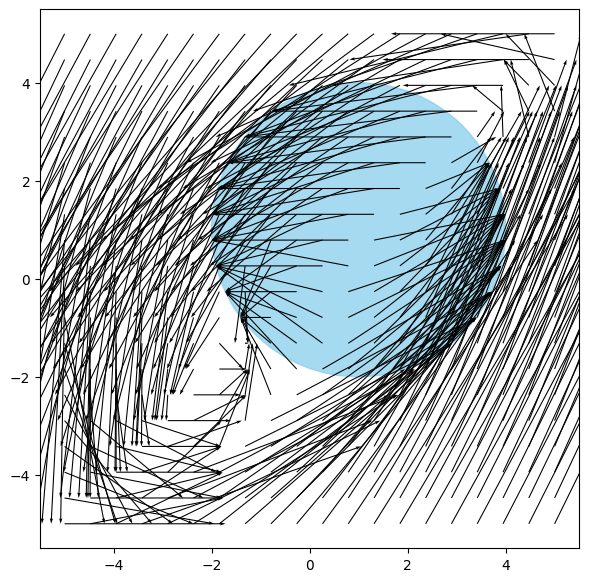

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.quiver(
    states[:, 0],
    states[:, 1],
    difference[:, 0],
    difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.002,
)
plt.show()

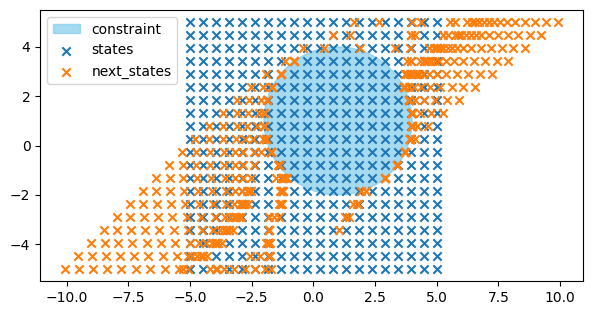

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.scatter(states[:, 0], states[:, 1], marker="x", label="states")
plt.scatter(next_states[:, 0], next_states[:, 1], marker="x", label="next_states")
plt.legend()
plt.show()

In [ ]:
policy_params = nnx.state(policy, nnx.Param)
problem = projection.get_problem(
    initial_state=center, policy_params=policy_params, jax_key=jax.random.key(42)
)
x_star = solver.solve(problem)
rollout = projection.get_rollout(x_star)

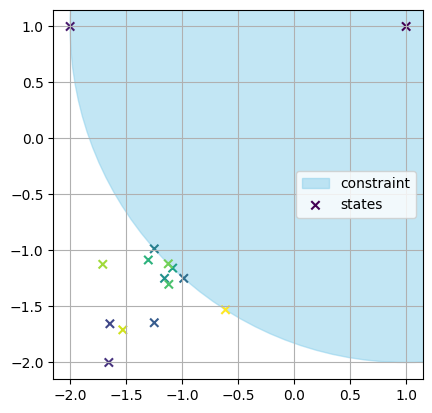

In [ ]:
# Create figure and axis
fig, ax = plt.subplots()
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
order = jnp.arange(len(rollout.states))
plt.scatter(
    rollout.states[:, 0], rollout.states[:, 1], c=order, cmap="viridis", marker="x", label="states"
)
ax.set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()

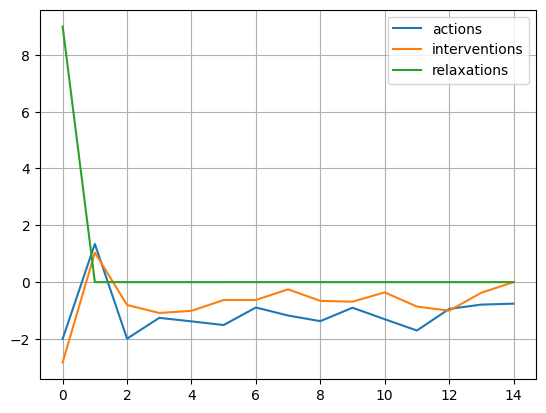

In [ ]:
fig, ax = plt.subplots()
plt.plot(rollout.actions, label="actions")
plt.plot(rollout.interventions, label="interventions")
plt.plot(rollout.relaxations, label="relaxations")
plt.legend()
plt.grid(True)
plt.show()